# Task 4: Charts for the LSTM
We draw three charts:
- How the model learned, epoch by epoch.
- The three kinds of LSTM.
- All our models together.
We save every chart as a picture in the report folder.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs('../report', exist_ok=True)
hist = pd.read_csv('../data/lstm_history.csv')
variants = pd.read_csv('../data/lstm_variants.csv')
comp = pd.read_csv('../data/model_comparison.csv')
HAM = '#2a78d6'
SPAM = '#eb6834'
print(hist.shape, variants.shape, comp.shape)
print(hist)

(6, 5) (3, 6) (4, 7)
   epoch  accuracy    loss  val_accuracy  val_loss
0      1    0.9006  0.3221        0.9671    0.1440
1      2    0.9732  0.1071        0.9464    0.1375
2      3    0.9890  0.0530        0.9829    0.0771
3      4    0.9966  0.0208        0.9817    0.0885
4      5    0.9973  0.0176        0.9683    0.1521
5      6    0.9936  0.0311        0.9805    0.0914


## 1. How the model learned
We draw two charts side by side: the loss and the accuracy.
The blue line is the train part, and the orange line is the validation part.
If the two lines go apart, the model is memorizing the train data.

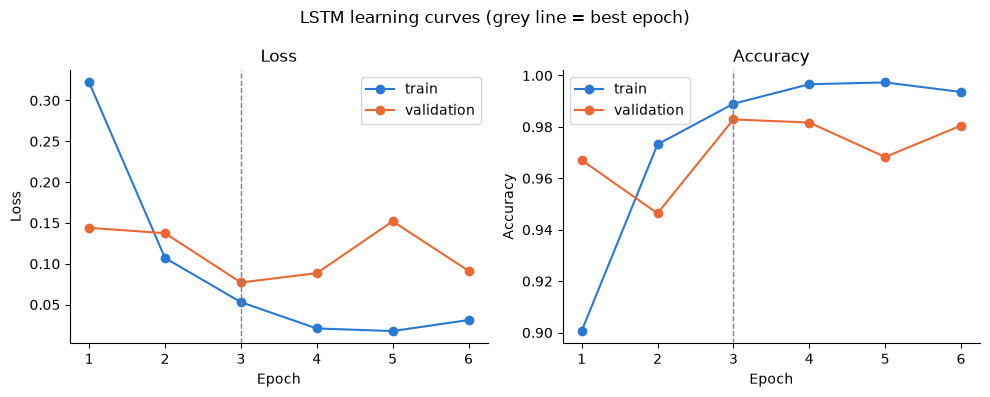

Best epoch: 3


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
best = int(hist.loc[hist['val_loss'].idxmin(), 'epoch'])
for ax, col, name in [(axes[0], 'loss', 'Loss'),
                      (axes[1], 'accuracy', 'Accuracy')]:
    ax.plot(hist['epoch'], hist[col], color=HAM, marker='o', label='train')
    ax.plot(hist['epoch'], hist['val_' + col], color=SPAM, marker='o', label='validation')
    ax.axvline(best, color='grey', linestyle='--', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Loss')
axes[1].set_ylabel('Accuracy')
plt.suptitle('LSTM learning curves (grey line = best epoch)')
plt.tight_layout()
plt.savefig('../report/chart5_lstm_learning.png', dpi=150)
plt.show()
print('Best epoch:', best)

## 2. The three kinds of LSTM
These results are on the validation part, not on the test data.

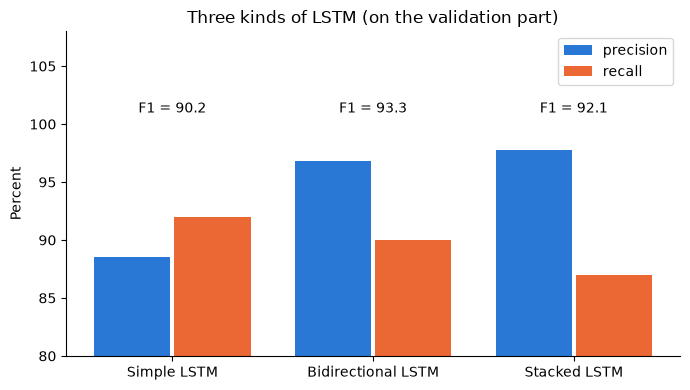

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(variants))
ax.bar([i - 0.2 for i in x], variants['precision'], width=0.38,
       color=HAM, label='precision')
ax.bar([i + 0.2 for i in x], variants['recall'], width=0.38,
       color=SPAM, label='recall')
for i, f in enumerate(variants['f1']):
    ax.text(i, 101, 'F1 = ' + str(f), ha='center')
ax.set_xticks(list(x))
ax.set_xticklabels(variants['model'])
ax.set_ylim(80, 108)
ax.set_ylabel('Percent')
ax.set_title('Three kinds of LSTM (on the validation part)')
ax.legend(loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../report/chart6_lstm_variants.png', dpi=150)
plt.show()

## 3. All our models together
This is on the test data (1,026 messages).
On the left: how good each model is.
On the right: the two kinds of mistakes.
A false alarm is a normal message sent to the spam box.
A missed message is a spam message that stayed in the inbox.

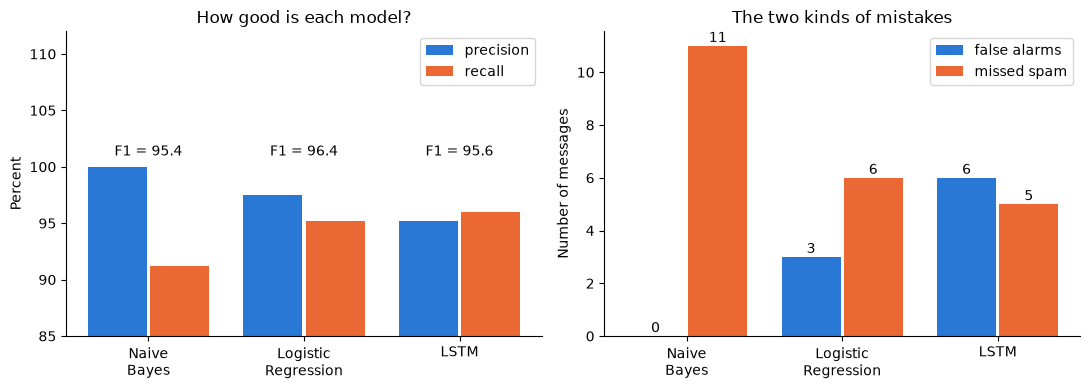

In [4]:
models = comp[comp['model'] != 'Always say ham']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = range(len(models))

ax = axes[0]
ax.bar([i - 0.2 for i in x], models['precision'], width=0.38,
       color=HAM, label='precision')
ax.bar([i + 0.2 for i in x], models['recall'], width=0.38,
       color=SPAM, label='recall')
for i, f in enumerate(models['f1']):
    ax.text(i, 101, 'F1 = ' + str(f), ha='center')
ax.set_xticks(list(x))
ax.set_xticklabels(['Naive\nBayes', 'Logistic\nRegression', 'LSTM'])
ax.set_ylim(85, 112)
ax.set_ylabel('Percent')
ax.set_title('How good is each model?')
ax.legend(loc='upper right')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.bar([i - 0.2 for i in x], models['false_alarms'], width=0.38,
       color=HAM, label='false alarms')
ax.bar([i + 0.2 for i in x], models['missed'], width=0.38,
       color=SPAM, label='missed spam')
for i, v in enumerate(models['false_alarms']):
    ax.text(i - 0.2, v + 0.15, str(v), ha='center')
for i, v in enumerate(models['missed']):
    ax.text(i + 0.2, v + 0.15, str(v), ha='center')
ax.set_xticks(list(x))
ax.set_xticklabels(['Naive\nBayes', 'Logistic\nRegression', 'LSTM'])
ax.set_ylabel('Number of messages')
ax.set_title('The two kinds of mistakes')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../report/chart7_all_models.png', dpi=150)
plt.show()